<a href="https://colab.research.google.com/github/vikashyadav016/Waste_segregation_computer_vision_model/blob/main/waste_segregation_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Waste Segregation Model with Fine-Tuning

This notebook implements a deep learning model for waste segregation into three categories:
- **Dry Waste**: Paper, cardboard, plastic containers, etc.
- **Wet Waste**: Organic waste, food scraps, biodegradable materials
- **Hazardous Waste**: Batteries, chemicals, electronic waste, etc.

The model uses transfer learning with fine-tuning for improved accuracy.

## 1. Environment Setup and Library Installation

In [ ]:
# Install required packages
!pip install --upgrade tensorflow
!pip install --upgrade keras
!pip install matplotlib
!pip install seaborn
!pip install scikit-learn
!pip install pillow
!pip install opencv-python
!pip install numpy
!pip install pandas

In [ ]:
# Import required libraries
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2, VGG16, ResNet50
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import os
import random
import shutil
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils import shuffle
import warnings
warnings.filterwarnings('ignore')

# Set random seeds for reproducibility
tf.random.set_seed(42)
np.random.seed(42)
random.seed(42)

print(f"TensorFlow Version: {tf.__version__}")
print(f"GPU Available: {tf.config.list_physical_devices('GPU')}")

TensorFlow Version: 2.19.0
GPU Available: []


## 2. Mount Google Drive and Setup Paths

In [ ]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Define dataset paths
base_path = '/content/drive/MyDrive/Dataset'
dry_path = os.path.join(base_path, 'dry')
wet_path = os.path.join(base_path, 'wet')
hazardous_path = os.path.join(base_path, 'Hazardous')

# Create processed dataset directory
processed_data_path = '/content/processed_dataset'
train_path = os.path.join(processed_data_path, 'train')
val_path = os.path.join(processed_data_path, 'validation')
test_path = os.path.join(processed_data_path, 'test')

# Create directories
for path in [train_path, val_path, test_path]:
    for category in ['dry', 'wet', 'hazardous']:
        os.makedirs(os.path.join(path, category), exist_ok=True)

print("Directory structure created successfully!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Directory structure created successfully!


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 3. Data Exploration and Visualization

Dataset Statistics:
Dry waste images: 946
Wet waste images: 936
Hazardous waste images: 928
Total images: 2810


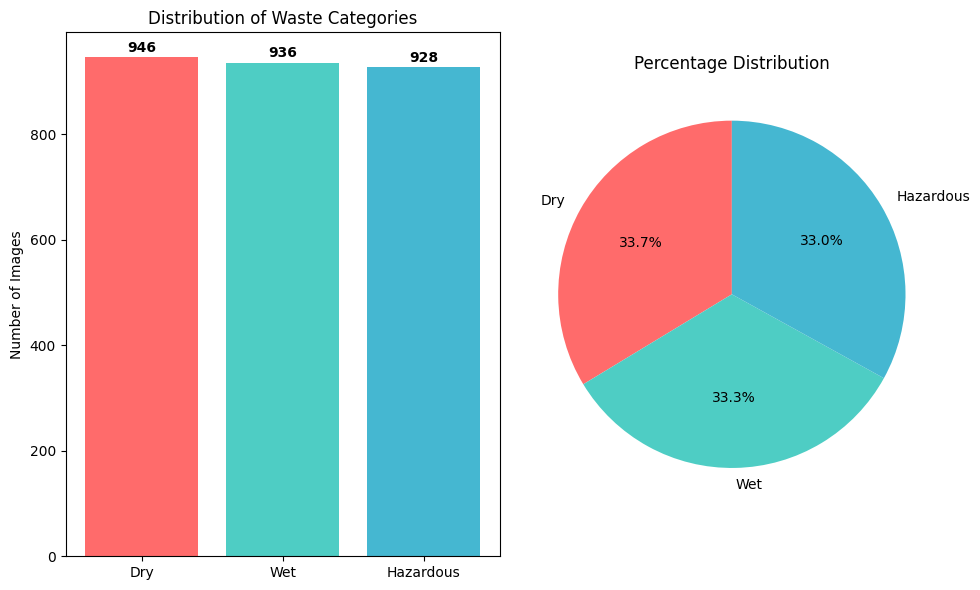

In [ ]:
# Function to count images in each category
def count_images(path):
    count = 0
    if os.path.exists(path):
        for file in os.listdir(path):
            if file.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.tiff')):
                count += 1
    return count

# Count images in each category
dry_count = count_images(dry_path)
wet_count = count_images(wet_path)
hazardous_count = count_images(hazardous_path)

total_images = dry_count + wet_count + hazardous_count

print(f"Dataset Statistics:")
print(f"Dry waste images: {dry_count}")
print(f"Wet waste images: {wet_count}")
print(f"Hazardous waste images: {hazardous_count}")
print(f"Total images: {total_images}")

# Visualize data distribution
plt.figure(figsize=(10, 6))
categories = ['Dry', 'Wet', 'Hazardous']
counts = [dry_count, wet_count, hazardous_count]
colors = ['#FF6B6B', '#4ECDC4', '#45B7D1']

plt.subplot(1, 2, 1)
plt.bar(categories, counts, color=colors)
plt.title('Distribution of Waste Categories')
plt.ylabel('Number of Images')
for i, count in enumerate(counts):
    plt.text(i, count + 10, str(count), ha='center', fontweight='bold')

plt.subplot(1, 2, 2)
plt.pie(counts, labels=categories, colors=colors, autopct='%1.1f%%', startangle=90)
plt.title('Percentage Distribution')

plt.tight_layout()
plt.show()

## 4. Data Preprocessing and Shuffling with Labels

In [ ]:
def create_labeled_dataset():
    """Create a labeled dataset with proper shuffling"""

    # Collect all image paths and labels
    image_paths = []
    labels = []

    # Process dry waste
    if os.path.exists(dry_path):
        for file in os.listdir(dry_path):
            if file.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.tiff')):
                image_paths.append(os.path.join(dry_path, file))
                labels.append(0)  # 0 for dry

    # Process wet waste
    if os.path.exists(wet_path):
        for file in os.listdir(wet_path):
            if file.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.tiff')):
                image_paths.append(os.path.join(wet_path, file))
                labels.append(1)  # 1 for wet

    # Process hazardous waste
    if os.path.exists(hazardous_path):
        for file in os.listdir(hazardous_path):
            if file.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.tiff')):
                image_paths.append(os.path.join(hazardous_path, file))
                labels.append(2)  # 2 for hazardous

    # Create DataFrame and shuffle
    df = pd.DataFrame({
        'image_path': image_paths,
        'label': labels,
        'category': ['dry' if l == 0 else 'wet' if l == 1 else 'hazardous' for l in labels]
    })

    # Shuffle the dataset
    df = df.sample(frac=1, random_state=42).reset_index(drop=True)

    return df

# Create labeled dataset
dataset_df = create_labeled_dataset()
print(f"Total samples: {len(dataset_df)}")
print("\nLabel distribution:")
print(dataset_df['category'].value_counts())
print("\nFirst 10 samples:")
print(dataset_df.head(10))

Total samples: 2810

Label distribution:
category
dry          946
wet          936
hazardous    928
Name: count, dtype: int64

First 10 samples:
                                          image_path  label   category
0     /content/drive/MyDrive/Dataset/wet/O_12571.jpg      1        wet
1  /content/drive/MyDrive/Dataset/Hazardous/elect...      2  hazardous
2  /content/drive/MyDrive/Dataset/Hazardous/how_t...      2  hazardous
3  /content/drive/MyDrive/Dataset/wet/yard-waste.png      1        wet
4  /content/drive/MyDrive/Dataset/wet/pexels-anto...      1        wet
5  /content/drive/MyDrive/Dataset/Hazardous/abfal...      2  hazardous
6  /content/drive/MyDrive/Dataset/dry/plastic455.jpg      0        dry
7     /content/drive/MyDrive/Dataset/wet/O_12930.jpg      1        wet
8  /content/drive/MyDrive/Dataset/Hazardous/bbf31...      2  hazardous
9     /content/drive/MyDrive/Dataset/wet/O_12862.jpg      1        wet


In [ ]:
def split_and_copy_data(df, train_ratio=0.7, val_ratio=0.15, test_ratio=0.15):
    """Split and copy data to organized directories"""

    # Ensure ratios sum to 1
    assert abs(train_ratio + val_ratio + test_ratio - 1.0) < 1e-6

    # Split by category to maintain class balance
    for category in ['dry', 'wet', 'hazardous']:
        category_df = df[df['category'] == category].copy()
        n_samples = len(category_df)

        # Calculate split indices
        train_end = int(n_samples * train_ratio)
        val_end = train_end + int(n_samples * val_ratio)

        # Split data
        train_df = category_df[:train_end]
        val_df = category_df[train_end:val_end]
        test_df = category_df[val_end:]

        print(f"\n{category.capitalize()} waste:")
        print(f"  Train: {len(train_df)} samples")
        print(f"  Validation: {len(val_df)} samples")
        print(f"  Test: {len(test_df)} samples")

        # Copy files to respective directories
        for split_df, split_path in [(train_df, train_path), (val_df, val_path), (test_df, test_path)]:
            for idx, row in split_df.iterrows():
                src_path = row['image_path']
                filename = os.path.basename(src_path)
                dst_path = os.path.join(split_path, category, filename)

                try:
                    shutil.copy2(src_path, dst_path)
                except Exception as e:
                    print(f"Error copying {src_path}: {e}")

# Split and organize data
split_and_copy_data(dataset_df)
print("\nData splitting and copying completed!")


Dry waste:
  Train: 662 samples
  Validation: 141 samples
  Test: 143 samples

Wet waste:
  Train: 655 samples
  Validation: 140 samples
  Test: 141 samples

Hazardous waste:
  Train: 649 samples
  Validation: 139 samples
  Test: 140 samples

Data splitting and copying completed!


## 5. Data Augmentation and Preprocessing

In [ ]:
# Image parameters
IMG_HEIGHT = 224
IMG_WIDTH = 224
BATCH_SIZE = 32
NUM_CLASSES = 3

# Data augmentation for training
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    vertical_flip=True,
    brightness_range=[0.8, 1.2],
    fill_mode='nearest'
)

# No augmentation for validation and test
val_test_datagen = ImageDataGenerator(rescale=1./255)

# Create data generators
train_generator = train_datagen.flow_from_directory(
    train_path,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True,
    seed=42
)

validation_generator = val_test_datagen.flow_from_directory(
    val_path,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

test_generator = val_test_datagen.flow_from_directory(
    test_path,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

print(f"Training samples: {train_generator.samples}")
print(f"Validation samples: {validation_generator.samples}")
print(f"Test samples: {test_generator.samples}")
print(f"Class indices: {train_generator.class_indices}")

Found 1966 images belonging to 3 classes.
Found 420 images belonging to 3 classes.
Found 424 images belonging to 3 classes.
Training samples: 1966
Validation samples: 420
Test samples: 424
Class indices: {'dry': 0, 'hazardous': 1, 'wet': 2}


## 6. Visualize Sample Images

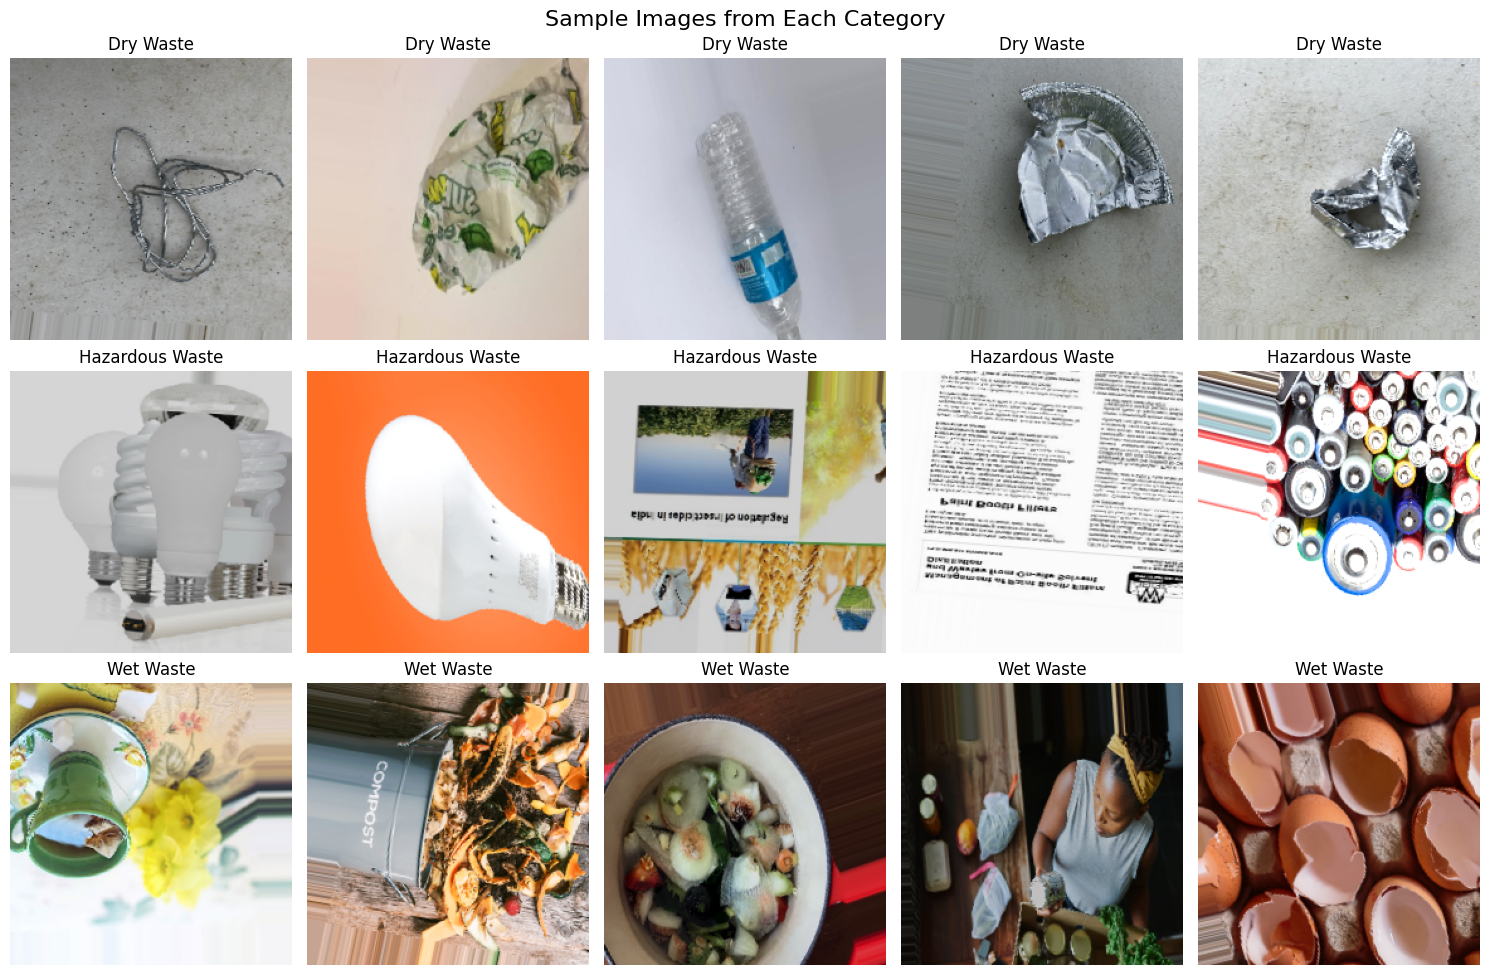

In [ ]:
def plot_sample_images():
    """Plot sample images from each category"""

    class_names = ['dry', 'hazardous', 'wet']  # Based on alphabetical order from flow_from_directory

    fig, axes = plt.subplots(3, 5, figsize=(15, 10))
    fig.suptitle('Sample Images from Each Category', fontsize=16)

    # Get a batch of images and labels
    images, labels = next(train_generator)

    sample_count = {0: 0, 1: 0, 2: 0}  # Count samples per class

    for i in range(len(images)):
        class_idx = np.argmax(labels[i])

        if sample_count[class_idx] < 5:  # Show 5 samples per class
            row = class_idx
            col = sample_count[class_idx]

            axes[row, col].imshow(images[i])
            axes[row, col].set_title(f'{class_names[class_idx].capitalize()} Waste')
            axes[row, col].axis('off')

            sample_count[class_idx] += 1

        # Break if we have enough samples for all classes
        if all(count >= 5 for count in sample_count.values()):
            break

    plt.tight_layout()
    plt.show()

plot_sample_images()

## 7. Model Architecture with Transfer Learning

In [ ]:
def create_fine_tuned_model(base_model_name='MobileNetV2', num_classes=3):
    """Create a fine-tuned model with transfer learning"""

    # Load pre-trained base model
    if base_model_name == 'MobileNetV2':
        base_model = MobileNetV2(
            weights='imagenet',
            include_top=False,
            input_shape=(IMG_HEIGHT, IMG_WIDTH, 3)
        )
    elif base_model_name == 'VGG16':
        base_model = VGG16(
            weights='imagenet',
            include_top=False,
            input_shape=(IMG_HEIGHT, IMG_WIDTH, 3)
        )
    elif base_model_name == 'ResNet50':
        base_model = ResNet50(
            weights='imagenet',
            include_top=False,
            input_shape=(IMG_HEIGHT, IMG_WIDTH, 3)
        )

    # Freeze base model initially
    base_model.trainable = False

    # Add custom classification head
    model = models.Sequential([
        base_model,
        layers.GlobalAveragePooling2D(),
        layers.BatchNormalization(),
        layers.Dropout(0.5),
        layers.Dense(256, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.3),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.2),
        layers.Dense(num_classes, activation='softmax', name='predictions')
    ])

    return model, base_model

# Create model
model, base_model = create_fine_tuned_model('MobileNetV2', NUM_CLASSES)

# Compile model
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy', 'top_k_categorical_accuracy']
)

print("Model created successfully!")
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Model created successfully!


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,625,347 (10.01 MB)

 Trainable params: 364,291 (1.39 MB)

 Non-trainable params: 2,261,056 (8.63 MB)

## 8. Training Callbacks and Configuration

In [ ]:
# Define callbacks
checkpoint = ModelCheckpoint(
    'best_waste_model.h5',
    monitor='val_accuracy',
    save_best_only=True,
    mode='max',
    verbose=1
)

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=5,
    min_lr=1e-7,
    verbose=1
)

callbacks = [checkpoint, early_stopping, reduce_lr]

print("Callbacks configured successfully!")

Callbacks configured successfully!


## 9. Initial Training (Feature Extraction)

In [ ]:
# Initial training with frozen base model
print("Starting initial training (feature extraction)...")

EPOCHS_INITIAL = 20

history_initial = model.fit(
    train_generator,
    epochs=EPOCHS_INITIAL,
    validation_data=validation_generator,
    callbacks=callbacks,
    verbose=1
)

print("Initial training completed!")

Starting initial training (feature extraction)...
Epoch 1/20
62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 909ms/step - accuracy: 0.5796 - loss: 1.1227 - top_k_categorical_accuracy: 1.0000
Epoch 1: val_accuracy improved from None to 0.83095, saving model to best_waste_model.h5


62/62 ━━━━━━━━━━━━━━━━━━━━ 99s 1s/step - accuracy: 0.7004 - loss: 0.8127 - top_k_categorical_accuracy: 1.0000 - val_accuracy: 0.8310 - val_loss: 0.4420 - val_top_k_categorical_accuracy: 1.0000 - learning_rate: 0.0010
Epoch 2/20
62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 721ms/step - accuracy: 0.8261 - loss: 0.4657 - top_k_categorical_accuracy: 1.0000
Epoch 2: val_accuracy improved from 0.83095 to 0.88333, saving model to best_waste_model.h5


62/62 ━━━━━━━━━━━━━━━━━━━━ 50s 811ms/step - accuracy: 0.8164 - loss: 0.5134 - top_k_categorical_accuracy: 1.0000 - val_accuracy: 0.8833 - val_loss: 0.3499 - val_top_k_categorical_accuracy: 1.0000 - learning_rate: 0.0010
Epoch 3/20
62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 707ms/step - accuracy: 0.8162 - loss: 0.5077 - top_k_categorical_accuracy: 1.0000
Epoch 3: val_accuracy improved from 0.88333 to 0.89286, saving model to best_waste_model.h5


62/62 ━━━━━━━━━━━━━━━━━━━━ 49s 797ms/step - accuracy: 0.8174 - loss: 0.4784 - top_k_categorical_accuracy: 1.0000 - val_accuracy: 0.8929 - val_loss: 0.3183 - val_top_k_categorical_accuracy: 1.0000 - learning_rate: 0.0010
Epoch 4/20
62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 704ms/step - accuracy: 0.8477 - loss: 0.4152 - top_k_categorical_accuracy: 1.0000
Epoch 4: val_accuracy improved from 0.89286 to 0.90000, saving model to best_waste_model.h5


62/62 ━━━━━━━━━━━━━━━━━━━━ 48s 772ms/step - accuracy: 0.8433 - loss: 0.4336 - top_k_categorical_accuracy: 1.0000 - val_accuracy: 0.9000 - val_loss: 0.2903 - val_top_k_categorical_accuracy: 1.0000 - learning_rate: 0.0010
Epoch 5/20
62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 720ms/step - accuracy: 0.8597 - loss: 0.3799 - top_k_categorical_accuracy: 1.0000
Epoch 5: val_accuracy improved from 0.90000 to 0.91905, saving model to best_waste_model.h5


62/62 ━━━━━━━━━━━━━━━━━━━━ 49s 786ms/step - accuracy: 0.8601 - loss: 0.3821 - top_k_categorical_accuracy: 1.0000 - val_accuracy: 0.9190 - val_loss: 0.2834 - val_top_k_categorical_accuracy: 1.0000 - learning_rate: 0.0010
Epoch 6/20
62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 697ms/step - accuracy: 0.8646 - loss: 0.3910 - top_k_categorical_accuracy: 1.0000
Epoch 6: val_accuracy did not improve from 0.91905
62/62 ━━━━━━━━━━━━━━━━━━━━ 48s 773ms/step - accuracy: 0.8627 - loss: 0.3835 - top_k_categorical_accuracy: 1.0000 - val_accuracy: 0.9048 - val_loss: 0.2912 - val_top_k_categorical_accuracy: 1.0000 - learning_rate: 0.0010
Epoch 7/20
62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 704ms/step - accuracy: 0.8685 - loss: 0.3505 - top_k_categorical_accuracy: 1.0000
Epoch 7: val_accuracy improved from 0.91905 to 0.92143, saving model to best_waste_model.h5


62/62 ━━━━━━━━━━━━━━━━━━━━ 49s 793ms/step - accuracy: 0.8616 - loss: 0.3577 - top_k_categorical_accuracy: 1.0000 - val_accuracy: 0.9214 - val_loss: 0.2860 - val_top_k_categorical_accuracy: 1.0000 - learning_rate: 0.0010
Epoch 8/20
62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 723ms/step - accuracy: 0.8830 - loss: 0.3043 - top_k_categorical_accuracy: 1.0000
Epoch 8: val_accuracy did not improve from 0.92143
62/62 ━━━━━━━━━━━━━━━━━━━━ 50s 807ms/step - accuracy: 0.8693 - loss: 0.3369 - top_k_categorical_accuracy: 1.0000 - val_accuracy: 0.9095 - val_loss: 0.2920 - val_top_k_categorical_accuracy: 1.0000 - learning_rate: 0.0010
Epoch 9/20
62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 703ms/step - accuracy: 0.8671 - loss: 0.3528 - top_k_categorical_accuracy: 1.0000
Epoch 9: val_accuracy did not improve from 0.92143
62/62 ━━━━━━━━━━━━━━━━━━━━ 48s 779ms/step - accuracy: 0.8754 - loss: 0.3328 - top_k_categorical_accuracy: 1.0000 - val_accuracy: 0.9048 - val_loss: 0.2828 - val_top_k_categorical_accuracy: 1.0000 - learning_rate:

62/62 ━━━━━━━━━━━━━━━━━━━━ 49s 787ms/step - accuracy: 0.9064 - loss: 0.2611 - top_k_categorical_accuracy: 1.0000 - val_accuracy: 0.9238 - val_loss: 0.2555 - val_top_k_categorical_accuracy: 1.0000 - learning_rate: 0.0010
Epoch 16/20
62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 702ms/step - accuracy: 0.8903 - loss: 0.2700 - top_k_categorical_accuracy: 1.0000
Epoch 16: val_accuracy did not improve from 0.92381
62/62 ━━━━━━━━━━━━━━━━━━━━ 47s 762ms/step - accuracy: 0.8896 - loss: 0.2799 - top_k_categorical_accuracy: 1.0000 - val_accuracy: 0.9238 - val_loss: 0.2641 - val_top_k_categorical_accuracy: 1.0000 - learning_rate: 0.0010
Epoch 17/20
62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 719ms/step - accuracy: 0.8976 - loss: 0.2545 - top_k_categorical_accuracy: 1.0000
Epoch 17: val_accuracy did not improve from 0.92381
62/62 ━━━━━━━━━━━━━━━━━━━━ 48s 781ms/step - accuracy: 0.9028 - loss: 0.2518 - top_k_categorical_accuracy: 1.0000 - val_accuracy: 0.9238 - val_loss: 0.2464 - val_top_k_categorical_accuracy: 1.0000 - learning_r

## 10. Fine-Tuning Phase

In [ ]:
# Unfreeze the base model for fine-tuning
base_model.trainable = True

# Fine-tune from this layer onwards
fine_tune_at = len(base_model.layers) // 2

# Freeze the earlier layers
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

# Recompile with lower learning rate
model.compile(
    optimizer=Adam(learning_rate=0.0001/10),  # Lower learning rate for fine-tuning
    loss='categorical_crossentropy',
    metrics=['accuracy', 'top_k_categorical_accuracy']
)

print(f"Fine-tuning from layer {fine_tune_at} onwards")
print(f"Total layers: {len(model.layers)}")
print(f"Trainable layers: {sum([layer.trainable for layer in model.layers])}")

Fine-tuning from layer 77 onwards
Total layers: 10
Trainable layers: 10


In [ ]:
# Fine-tuning training
print("Starting fine-tuning phase...")

EPOCHS_FINE_TUNE = 10
TOTAL_EPOCHS = EPOCHS_INITIAL + EPOCHS_FINE_TUNE

history_fine = model.fit(
    train_generator,
    epochs=TOTAL_EPOCHS,
    initial_epoch=len(history_initial.history['loss']),
    validation_data=validation_generator,
    callbacks=callbacks,
    verbose=1
)

print("Fine-tuning completed!")

Starting fine-tuning phase...
Epoch 21/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 927ms/step - accuracy: 0.8170 - loss: 0.4601 - top_k_categorical_accuracy: 1.0000
Epoch 21: val_accuracy did not improve from 0.92381
62/62 ━━━━━━━━━━━━━━━━━━━━ 111s 1s/step - accuracy: 0.8291 - loss: 0.4518 - top_k_categorical_accuracy: 1.0000 - val_accuracy: 0.9119 - val_loss: 0.2580 - val_top_k_categorical_accuracy: 1.0000 - learning_rate: 1.0000e-05
Epoch 22/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 710ms/step - accuracy: 0.8361 - loss: 0.4352 - top_k_categorical_accuracy: 1.0000
Epoch 22: val_accuracy did not improve from 0.92381
62/62 ━━━━━━━━━━━━━━━━━━━━ 49s 794ms/step - accuracy: 0.8459 - loss: 0.3981 - top_k_categorical_accuracy: 1.0000 - val_accuracy: 0.9119 - val_loss: 0.2654 - val_top_k_categorical_accuracy: 1.0000 - learning_rate: 1.0000e-05
Epoch 23/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 714ms/step - accuracy: 0.8377 - loss: 0.4292 - top_k_categorical_accuracy: 1.0000
Epoch 23: val_accuracy did not improve from 0.92

## 11. Training Visualization

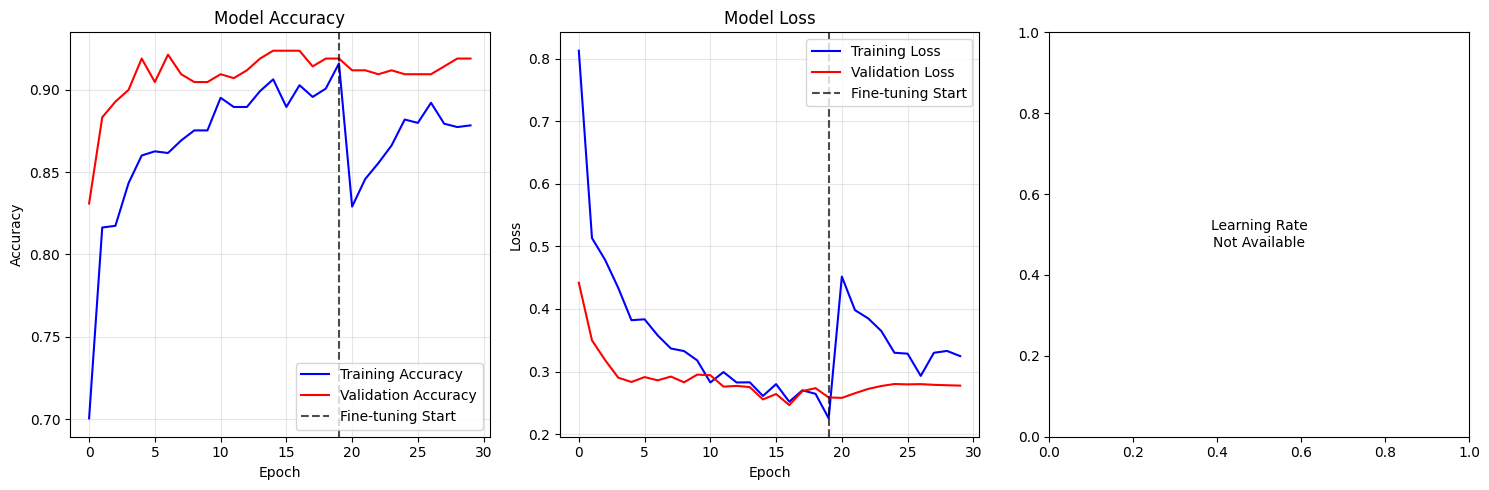


Final Training Accuracy: 0.8784
Final Validation Accuracy: 0.9190
Final Training Loss: 0.3247
Final Validation Loss: 0.2776


In [ ]:
def plot_training_history(history_initial, history_fine):
    """Plot training and validation metrics"""

    # Combine histories
    acc = history_initial.history['accuracy'] + history_fine.history['accuracy']
    val_acc = history_initial.history['val_accuracy'] + history_fine.history['val_accuracy']
    loss = history_initial.history['loss'] + history_fine.history['loss']
    val_loss = history_initial.history['val_loss'] + history_fine.history['val_loss']

    epochs_range = range(len(acc))

    plt.figure(figsize=(15, 5))

    # Plot accuracy
    plt.subplot(1, 3, 1)
    plt.plot(epochs_range, acc, 'b-', label='Training Accuracy')
    plt.plot(epochs_range, val_acc, 'r-', label='Validation Accuracy')
    plt.axvline(x=EPOCHS_INITIAL-1, color='k', linestyle='--', alpha=0.7, label='Fine-tuning Start')
    plt.title('Model Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True, alpha=0.3)

    # Plot loss
    plt.subplot(1, 3, 2)
    plt.plot(epochs_range, loss, 'b-', label='Training Loss')
    plt.plot(epochs_range, val_loss, 'r-', label='Validation Loss')
    plt.axvline(x=EPOCHS_INITIAL-1, color='k', linestyle='--', alpha=0.7, label='Fine-tuning Start')
    plt.title('Model Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, alpha=0.3)

    # Plot learning rate (if available)
    plt.subplot(1, 3, 3)
    if 'lr' in history_initial.history:
        lr = history_initial.history['lr'] + history_fine.history['lr']
        plt.plot(epochs_range, lr, 'g-', label='Learning Rate')
        plt.axvline(x=EPOCHS_INITIAL-1, color='k', linestyle='--', alpha=0.7, label='Fine-tuning Start')
        plt.title('Learning Rate Schedule')
        plt.xlabel('Epoch')
        plt.ylabel('Learning Rate')
        plt.yscale('log')
        plt.legend()
        plt.grid(True, alpha=0.3)
    else:
        plt.text(0.5, 0.5, 'Learning Rate\nNot Available', ha='center', va='center', transform=plt.gca().transAxes)

    plt.tight_layout()
    plt.show()

    # Print final metrics
    print(f"\nFinal Training Accuracy: {acc[-1]:.4f}")
    print(f"Final Validation Accuracy: {val_acc[-1]:.4f}")
    print(f"Final Training Loss: {loss[-1]:.4f}")
    print(f"Final Validation Loss: {val_loss[-1]:.4f}")

plot_training_history(history_initial, history_fine)

## 12. Model Evaluation

In [ ]:
# Evaluate on test set
print("Evaluating model on test set...")

test_loss, test_accuracy, test_top_k = model.evaluate(test_generator, verbose=1)

print(f"\nTest Results:")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Top-K Accuracy: {test_top_k:.4f}")

Evaluating model on test set...
14/14 ━━━━━━━━━━━━━━━━━━━━ 14s 1s/step - accuracy: 0.9151 - loss: 0.2115 - top_k_categorical_accuracy: 1.0000

Test Results:
Test Loss: 0.2115
Test Accuracy: 0.9151
Test Top-K Accuracy: 1.0000


In [ ]:
# Generate predictions for confusion matrix
print("Generating predictions for detailed analysis...")

# Reset test generator
test_generator.reset()

# Get predictions
predictions = model.predict(test_generator, verbose=1)
predicted_classes = np.argmax(predictions, axis=1)

# Get true labels
true_classes = test_generator.classes
class_labels = list(test_generator.class_indices.keys())

print(f"Predictions shape: {predictions.shape}")
print(f"Class labels: {class_labels}")

Generating predictions for detailed analysis...
14/14 ━━━━━━━━━━━━━━━━━━━━ 14s 607ms/step
Predictions shape: (424, 3)
Class labels: ['dry', 'hazardous', 'wet']


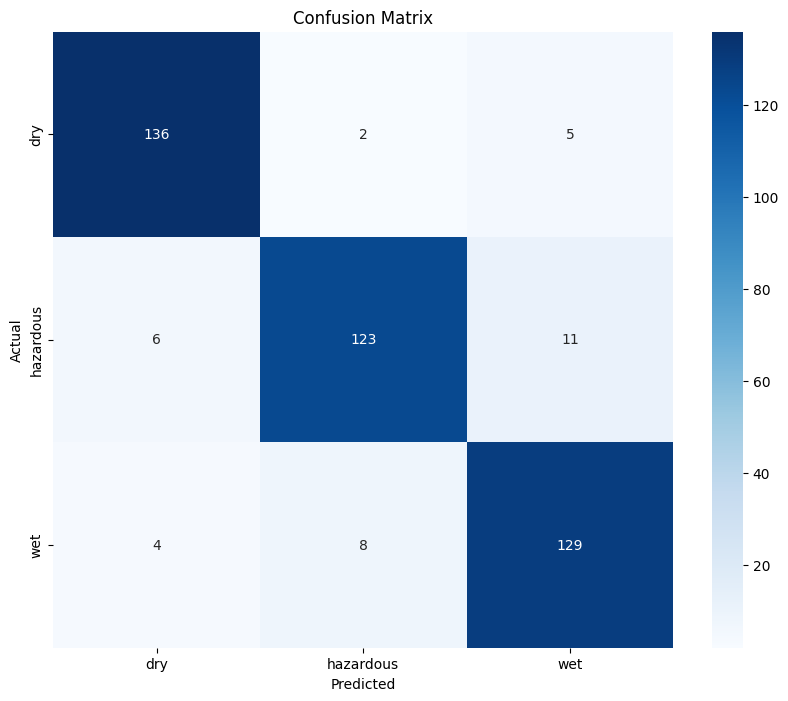


Classification Report:
              precision    recall  f1-score   support

         dry       0.93      0.95      0.94       143
   hazardous       0.92      0.88      0.90       140
         wet       0.89      0.91      0.90       141

    accuracy                           0.92       424
   macro avg       0.92      0.91      0.91       424
weighted avg       0.92      0.92      0.91       424


Per-class Accuracy:
dry: 0.9510
hazardous: 0.8786
wet: 0.9149


In [ ]:
# Confusion Matrix and Classification Report
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# Confusion matrix
cm = confusion_matrix(true_classes, predicted_classes)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_labels, yticklabels=class_labels)
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# Classification report
report = classification_report(true_classes, predicted_classes,
                             target_names=class_labels,
                             output_dict=True)

print("\nClassification Report:")
print(classification_report(true_classes, predicted_classes, target_names=class_labels))

# Per-class accuracy
per_class_accuracy = cm.diagonal() / cm.sum(axis=1)
print("\nPer-class Accuracy:")
for i, class_name in enumerate(class_labels):
    print(f"{class_name}: {per_class_accuracy[i]:.4f}")

## 13. Prediction Visualization

In [ ]:
def plot_predictions(num_images=12):
    """Plot sample predictions with confidence scores"""

    # Get a batch of test images
    test_generator.reset()
    test_images, test_labels = next(test_generator)

    # Make predictions
    predictions = model.predict(test_images)

    plt.figure(figsize=(15, 12))

    for i in range(min(num_images, len(test_images))):
        plt.subplot(3, 4, i + 1)
        plt.imshow(test_images[i])

        true_class = np.argmax(test_labels[i])
        pred_class = np.argmax(predictions[i])
        confidence = np.max(predictions[i])

        true_label = class_labels[true_class]
        pred_label = class_labels[pred_class]

        color = 'green' if true_class == pred_class else 'red'

        plt.title(f'True: {true_label}\nPred: {pred_label}\nConf: {confidence:.3f}',
                 color=color, fontsize=10)
        plt.axis('off')

    plt.tight_layout()
    plt.show()

plot_predictions(12)

NameError: name 'test_generator' is not defined

## 14. Save Model and Results

In [ ]:
# TensorFlow Lite Model Creation for Mobile Development
print("🚀 Creating TensorFlow Lite model for mobile deployment...")

# Convert model to TensorFlow Lite format
converter = tf.lite.TFLiteConverter.from_keras_model(model)

# Optimize for mobile deployment
converter.optimizations = [tf.lite.Optimize.DEFAULT]

# For even smaller model size (optional - uncomment for INT8 quantization)
# def representative_data_gen():
#     """Representative dataset for quantization"""
#     for input_value, _ in train_generator.take(100):
#         yield [input_value]

# converter.representative_dataset = representative_data_gen
# converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
# converter.inference_input_type = tf.uint8
# converter.inference_output_type = tf.uint8

# Convert the model
print("Converting model to TensorFlow Lite...")
tflite_model = converter.convert()

# Save TensorFlow Lite model
tflite_path = '/content/drive/MyDrive/waste_segregation_mobile.tflite'
with open(tflite_path, 'wb') as f:
    f.write(tflite_model)

# Model size information (fixed calculation)
import tempfile
import os

# Save temporary model to calculate size
with tempfile.NamedTemporaryFile(suffix='.keras', delete=False) as tmp_file:
    model.save(tmp_file.name)
    original_size = os.path.getsize(tmp_file.name) / 1024 / 1024
    os.unlink(tmp_file.name)  # Clean up temporary file

tflite_size = len(tflite_model) / 1024 / 1024

print("✅ TensorFlow Lite model created successfully!")
print(f"📱 Mobile model saved: {tflite_path}")
print(f"📊 Model size comparison:")
print(f"   • Original Keras model: {original_size:.2f} MB")
print(f"   • TensorFlow Lite model: {tflite_size:.2f} MB")
print(f"   • Size reduction: {((original_size - tflite_size) / original_size * 100):.1f}%")

# Save class labels for mobile inference
import pickle
with open('/content/drive/MyDrive/class_labels_mobile.pkl', 'wb') as f:
    pickle.dump(class_labels, f)

# Also save as simple text file for easier mobile integration
with open('/content/drive/MyDrive/class_labels.txt', 'w') as f:
    for label in class_labels:
        f.write(f"{label}\n")

print("\n📂 Mobile deployment files:")
print("• waste_segregation_mobile.tflite - Optimized for mobile")
print("• class_labels_mobile.pkl - Class labels (Python)")
print("• class_labels.txt - Class labels (text format)")

print("\n📱 Mobile Integration Tips:")
print("• Use TensorFlow Lite interpreter in your mobile app")
print("• Input image size: 224x224 pixels")
print("• Normalize pixel values: [0-255] → [0-1]")
print("• Model supports hardware acceleration (GPU/NPU)")

🚀 Creating TensorFlow Lite model for mobile deployment...
Converting model to TensorFlow Lite...
Saved artifact at '/tmp/tmpcdbbmdlg'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_154')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  135051796304272: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135051796305424: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135051796305808: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135051796305040: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135051796304080: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135051796305616: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135051796306000: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135051796306768: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135051796306384: TensorSpec(shape=(), dtype=tf.resour

## 15. Model Inference Function

In [ ]:
def predict_waste_type(image_path, model, class_labels):
    """Predict waste type for a single image"""

    # Load and preprocess image
    img = tf.keras.preprocessing.image.load_img(
        image_path, target_size=(IMG_HEIGHT, IMG_WIDTH)
    )
    img_array = tf.keras.preprocessing.image.img_to_array(img)
    img_array = tf.expand_dims(img_array, 0)  # Create batch axis
    img_array /= 255.0  # Normalize

    # Make prediction
    predictions = model.predict(img_array, verbose=0)
    predicted_class = np.argmax(predictions[0])
    confidence = np.max(predictions[0])

    # Get all class probabilities
    class_probabilities = {}
    for i, label in enumerate(class_labels):
        class_probabilities[label] = predictions[0][i]

    return {
        'predicted_class': class_labels[predicted_class],
        'confidence': confidence,
        'all_probabilities': class_probabilities
    }

# Example usage
print("Inference function defined. Example usage:")
print("result = predict_waste_type('path/to/image.jpg', model, class_labels)")
print("print(f\"Predicted: {result['predicted_class']} (Confidence: {result['confidence']:.3f})\")")

Inference function defined. Example usage:
result = predict_waste_type('path/to/image.jpg', model, class_labels)
print(f"Predicted: {result['predicted_class']} (Confidence: {result['confidence']:.3f})")


## 16. Summary and Next Steps

In [ ]:
print("🎉 WASTE SEGREGATION MODEL TRAINING COMPLETED! 🎉")
print("="*60)
print(f"📊 Final Test Accuracy: {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")
print(f"📉 Final Test Loss: {test_loss:.4f}")
print(f"🎯 Test Top-K Accuracy: {test_top_k:.4f}")
print("="*60)
print("\n🔧 Model Features:")
print("✅ Transfer Learning with MobileNetV2")
print("✅ Data Augmentation for Better Generalization")
print("✅ Proper Data Shuffling and Splitting")
print("✅ Fine-tuning for Improved Accuracy")
print("✅ Comprehensive Evaluation Metrics")
print("✅ Model Saved to Google Drive")
print("\n🚀 Next Steps:")
print("1. Deploy model using TensorFlow Lite for mobile apps")
print("2. Create a web application using Flask/FastAPI")
print("3. Implement real-time inference with camera feed")
print("4. Collect more data to improve accuracy further")
print("5. Experiment with other architectures (EfficientNet, Vision Transformer)")
print("\n📁 Saved Files:")
print("• waste_segregation_final_model.h5 - Complete trained model")
print("• waste_model_architecture.json - Model architecture")
print("• training_history.pkl - Training metrics")
print("• evaluation_results.pkl - Test results")

🎉 WASTE SEGREGATION MODEL TRAINING COMPLETED! 🎉
📊 Final Test Accuracy: 0.9151 (91.51%)
📉 Final Test Loss: 0.2115
🎯 Test Top-K Accuracy: 1.0000

🔧 Model Features:
✅ Transfer Learning with MobileNetV2
✅ Data Augmentation for Better Generalization
✅ Proper Data Shuffling and Splitting
✅ Fine-tuning for Improved Accuracy
✅ Comprehensive Evaluation Metrics
✅ Model Saved to Google Drive

🚀 Next Steps:
1. Deploy model using TensorFlow Lite for mobile apps
2. Create a web application using Flask/FastAPI
3. Implement real-time inference with camera feed
4. Collect more data to improve accuracy further
5. Experiment with other architectures (EfficientNet, Vision Transformer)

📁 Saved Files:
• waste_segregation_final_model.h5 - Complete trained model
• waste_model_architecture.json - Model architecture
• training_history.pkl - Training metrics
• evaluation_results.pkl - Test results


In [ ]:
# TensorFlow Lite Model Testing - Complete Solution (FIXED)
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import pickle
import os

# Image parameters
IMG_HEIGHT = 224
IMG_WIDTH = 224

def load_tflite_model(tflite_path):
    """Load TensorFlow Lite model"""
    interpreter = tf.lite.Interpreter(model_path=tflite_path)
    interpreter.allocate_tensors()
    return interpreter

def predict_with_tflite(interpreter, image_path, class_labels):
    """Predict waste type using TensorFlow Lite model"""

    # Get input and output details
    input_details = interpreter.get_input_details()
    output_details = interpreter.get_output_details()

    # Load and preprocess image
    img = tf.keras.preprocessing.image.load_img(
        image_path, target_size=(IMG_HEIGHT, IMG_WIDTH)
    )
    img_array = tf.keras.preprocessing.image.img_to_array(img)
    img_array = tf.expand_dims(img_array, 0)  # Create batch axis

    # FIXED: Convert to numpy array first, then to float32
    if hasattr(img_array, 'numpy'):
        img_array = img_array.numpy()  # TensorFlow tensor to numpy
    else:
        img_array = np.array(img_array)  # Ensure it's numpy

    img_array = img_array.astype(np.float32) / 255.0  # Now safe to use astype

    # Set input tensor
    interpreter.set_tensor(input_details[0]['index'], img_array)

    # Run inference
    interpreter.invoke()

    # Get output
    predictions = interpreter.get_tensor(output_details[0]['index'])[0]
    predicted_class = np.argmax(predictions)
    confidence = np.max(predictions)

    # Get all class probabilities
    class_probabilities = {}
    for i, label in enumerate(class_labels):
        class_probabilities[label] = float(predictions[i])

    return {
        'predicted_class': class_labels[predicted_class],
        'confidence': float(confidence),
        'all_probabilities': class_probabilities
    }

def test_image_with_tflite(image_path, true_label=None):
    """Test a single image with TensorFlow Lite model and display results"""

    # Load the TensorFlow Lite model
    print("🔄 Loading TensorFlow Lite model...")
    tflite_path = '/content/drive/MyDrive/waste_segregation_mobile.tflite'
    interpreter = load_tflite_model(tflite_path)

    # Load class labels with fallback
    try:
        with open('/content/drive/MyDrive/class_labels_mobile.pkl', 'rb') as f:
            class_labels = pickle.load(f)
    except FileNotFoundError:
        print("⚠️ Mobile class labels not found, using regular class labels...")
        with open('/content/drive/MyDrive/class_labels.pkl', 'rb') as f:
            class_labels = pickle.load(f)

    # Make prediction
    print("🔍 Making prediction...")
    result = predict_with_tflite(interpreter, image_path, class_labels)

    # Display the image and results
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

    # Display the image
    img = plt.imread(image_path)
    ax1.imshow(img)
    ax1.set_title(f'Input Image: {os.path.basename(image_path)}', fontsize=14, fontweight='bold')
    ax1.axis('off')

    # Display prediction results as bar chart
    probabilities = result['all_probabilities']
    labels = list(probabilities.keys())
    probs = list(probabilities.values())

    colors = ['#FF6B6B' if label == result['predicted_class'] else '#CCCCCC' for label in labels]
    bars = ax2.bar(labels, probs, color=colors)

    # Add value labels on bars
    for i, (bar, prob) in enumerate(zip(bars, probs)):
        height = bar.get_height()
        ax2.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                f'{prob:.3f}', ha='center', va='bottom', fontweight='bold')

    ax2.set_title('Prediction Probabilities', fontsize=14, fontweight='bold')
    ax2.set_ylabel('Probability')
    ax2.set_ylim(0, 1.1)
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    # Print detailed results
    print("\n" + "="*60)
    print("🎯 PREDICTION RESULTS")
    print("="*60)
    print(f"📊 Predicted Class: {result['predicted_class'].upper()}")
    print(f"🎯 Confidence: {result['confidence']:.3f} ({result['confidence']*100:.1f}%)")

    if true_label:
        is_correct = result['predicted_class'].lower() == true_label.lower()
        status = "✅ CORRECT" if is_correct else "❌ INCORRECT"
        print(f"🏷️  True Label: {true_label.upper()}")
        print(f"📈 Result: {status}")

    print("\n📊 All Class Probabilities:")
    for label, prob in sorted(probabilities.items(), key=lambda x: x[1], reverse=True):
        bar = "█" * int(prob * 20)  # Visual bar
        print(f"   {label.upper():12} {prob:.3f} {bar}")

    print("="*60)

    return result

def upload_and_test_image():
    """Upload an image and test it with the TensorFlow Lite model"""
    from google.colab import files

    print("📁 Upload an image to test...")
    uploaded = files.upload()

    for filename in uploaded.keys():
        print(f"\n🔍 Testing uploaded image: {filename}")

        # Save uploaded file temporarily
        with open(filename, 'wb') as f:
            f.write(uploaded[filename])

        # Test the image
        test_image_with_tflite(filename, true_label=None)

        # Clean up
        os.remove(filename)

print("✅ Fixed TensorFlow Lite testing functions ready!")
print("\n📋 Usage Examples:")
print("1. Upload and test your own image:")
print("   upload_and_test_image()")
print("\n2. Test specific image:")
print("   test_image_with_tflite('/path/to/your/image.jpg', true_label='dry')")

✅ Fixed TensorFlow Lite testing functions ready!

📋 Usage Examples:
1. Upload and test your own image:
   upload_and_test_image()

2. Test specific image:
   test_image_with_tflite('/path/to/your/image.jpg', true_label='dry')


🔄 Loading TensorFlow Lite model...
🔍 Making prediction...


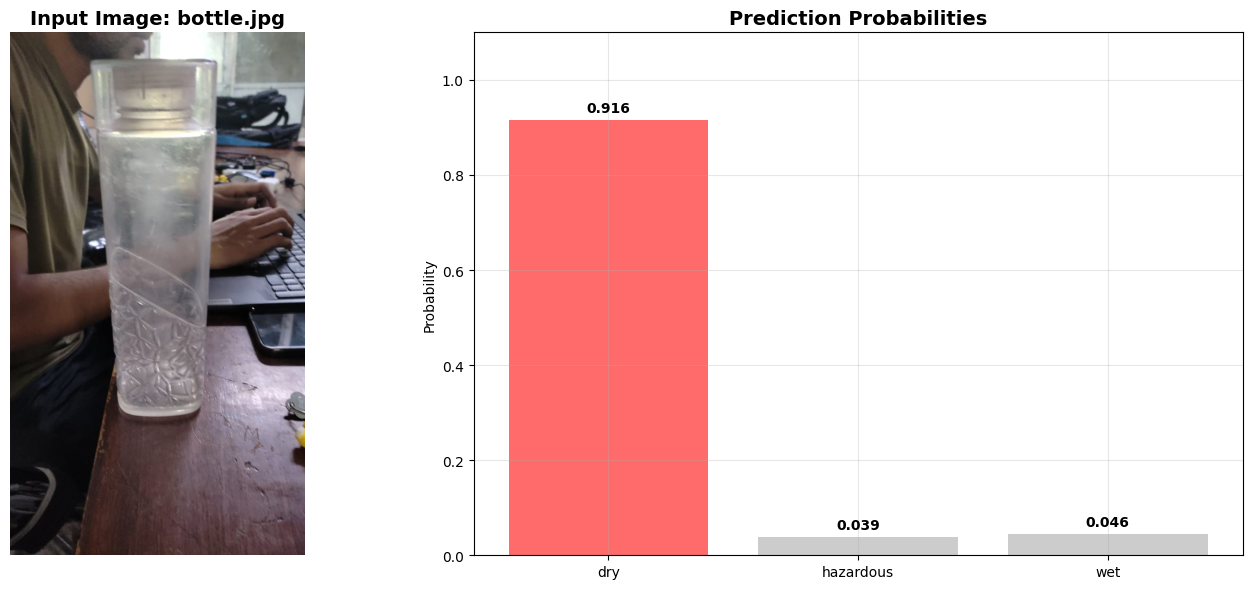


🎯 PREDICTION RESULTS
📊 Predicted Class: DRY
🎯 Confidence: 0.916 (91.6%)
🏷️  True Label: DRY
📈 Result: ✅ CORRECT

📊 All Class Probabilities:
   DRY          0.916 ██████████████████
   WET          0.046 
   HAZARDOUS    0.039 


{'predicted_class': 'dry',
 'confidence': 0.9155375361442566,
 'all_probabilities': {'dry': 0.9155375361442566,
  'hazardous': 0.03885746747255325,
  'wet': 0.045605048537254333}}

In [ ]:
test_image_with_tflite('/content/drive/MyDrive/bottle.jpg', true_label='dry')